# Parte I: Planteo del caso y selección de dataset.

Analizar el impacto que conlleva el uso de las redes sociales en el bienestar estudiantil.

## Objetivos

1.  ¿Existe una relación entre las horas de uso diario de redes sociales y el nivel de estrés?
2. ¿Cuál es la calidad de sueño que presentan los estudiantes que utilizan las redes sociales durante la noche?
3. ¿Cuál es la plataforma más utilizada por los estudiantes según su nivel académico?
4. ¿Cómo varía el rendimiento académico según el tiempo de uso de las redes sociales?


## Dataset - Impact of Social Media on Life

> Este conjunto de datos proporciona métricas detalladas de encuestas a 4.500 estudiantes, desde programas de secundaria hasta posgrado, para analizar cómo la participación digital moldea la vida diaria y el bienestar.

[Fuente del dataset](https://www.kaggle.com/datasets/harishyadav0506/impact-of-social-media-on-life?resource=download)



## Diccionario de columnas.

* **Age**: Edad del participante (15 a 26 años)
* **Gender**: Categoría de género autodeclarada
* **Academic_Level**: Secundaria, Grado o Posgrado
* **Primary_Platform**: Plataforma digital más utilizada
* **Daily_Usage_Hours**: Tiempo medio diario frente a pantalla en redes sociales (horas)
* **Weekend_Extra_Hours**: Tiempo de pantalla suplementario durante los fines de semana
* **Device_Type**: Dispositivo principal utilizado para el acceso
* **Sleep_Duration_Hours**: Duración media del sueño nocturno
* **Sleep_Quality_Score**: Calidad del sueño autoevaluada (escala del 1 al 5)
* **Late_Night_Usage**: Frecuente tiempo frente a pantallas después de medianoche
* **Social_Comparison_Frequency**: Frecuencia de los comportamientos de comparación social
* **Perceived_Stress_Score**: Indicador de estrés psicométrico PSS (0 a 40)
* **Mental_Health_Index**: Métrica compuesta de bienestar (10 a 98)
* **Academic_Performance_GPA**: GPA acumulado (Escala: 1,70 a 4,00)
* **Overall_Impact**: Resultado de clasificación multifactorial

# Parte II: Limpieza y análisis exploratorio en Python.



## 2.1 Carga del dataset.

In [ ]:
import pandas as pd

In [ ]:
df_impacto=pd.read_csv("/content/drive/MyDrive/Trabajo final curso/Social_media_impact_on_life.csv")

## 2.2 Exploración estructural

In [ ]:
# Cantidad de filas y columnas
print("Filas y columnas:",df_impacto.shape)
print("Nombres de columnas:", list(df_impacto.columns))

Filas y columnas: (4500, 16)
Nombres de columnas: ['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Primary_Platform', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Device_Type', 'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Late_Night_Usage', 'Social_Comparison_Frequency', 'Perceived_Stress_Score', 'Mental_Health_Index', 'Academic_Performance_GPA', 'Overall_Impact']


In [ ]:
# tipos de datos + cantidad de valores no nulos por columna
df_impacto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   object 
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   object 
 3   Academic_Level               4500 non-null   object 
 4   Primary_Platform             4500 non-null   object 
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   object 
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   object 
 12  Perceived_Stress_Score       4454 non-null   float64
 13  Mental_Health_Inde

In [ ]:
# Tipos de variables.

df_impacto.dtypes

,0
Student_ID,object
Age,int64
Gender,object
Academic_Level,object
Primary_Platform,object
Daily_Usage_Hours,float64
Weekend_Extra_Hours,float64
Device_Type,object
Sleep_Duration_Hours,float64
Sleep_Quality_Score,int64


In [ ]:
# Primeros 5 filas de la base de datos.
df_impacto.head()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


## 2.3 Limpieza

In [ ]:
# Identificación de duplicados

df_impacto.duplicated().sum()

np.int64(0)

In [ ]:
# Identificación de nulos

df_impacto.isnull().sum()

,0
Student_ID,0
Age,0
Gender,0
Academic_Level,0
Primary_Platform,0
Daily_Usage_Hours,0
Weekend_Extra_Hours,0
Device_Type,0
Sleep_Duration_Hours,0
Sleep_Quality_Score,0


Se identificaron pocos valores nulos en las variables Perceived_Stress_Score (46 registros) y Academic_Performance_GPA (85 registros), debido a eso se imputo la la mediana

In [ ]:
for col in ["Perceived_Stress_Score", "Academic_Performance_GPA"]:
    df_impacto[col] = df_impacto[col].fillna(df_impacto[col].median())

df_impacto.isnull().sum()

,0
Student_ID,0
Age,0
Gender,0
Academic_Level,0
Primary_Platform,0
Daily_Usage_Hours,0
Weekend_Extra_Hours,0
Device_Type,0
Sleep_Duration_Hours,0
Sleep_Quality_Score,0


## 2.4 Exploracion estadística

In [ ]:
# Estandarización de categorías
for col in ["Gender",
            "Academic_Level",
            "Primary_Platform",
            "Device_Type",
            "Social_Comparison_Frequency",
            "Overall_Impact"]:
    print(f"\n{col}")
    print(df_impacto[col].unique())


Gender
['Female' 'Male' 'Non-Binary' 'Prefer not to say']

Academic_Level
['Undergraduate' 'High School' 'Postgraduate']

Primary_Platform
['Snapchat' 'Instagram' 'TikTok' 'YouTube' 'LinkedIn' 'Reddit'
 'X (Twitter)']

Device_Type
['Smartphone' 'Tablet' 'Laptop/PC']

Social_Comparison_Frequency
['Always' 'Sometimes' 'Frequently' 'Never' 'Rarely']

Overall_Impact
['Neutral' 'Beneficial' 'Negative']


 No se encontraron inconsistencias significativas, por lo que no fue necesaria una transformación adicional.

In [ ]:
# Frecuencia de categorías:
print(df_impacto["Primary_Platform"].value_counts())
print()
print(df_impacto["Device_Type"].value_counts())
print()
print(df_impacto["Gender"].value_counts())

Primary_Platform
Instagram      1453
TikTok         1226
YouTube         818
Snapchat        472
Reddit          229
X (Twitter)     206
LinkedIn         96
Name: count, dtype: int64

Device_Type
Smartphone    3775
Laptop/PC      596
Tablet         129
Name: count, dtype: int64

Gender
Female               2234
Male                 2051
Non-Binary            122
Prefer not to say      93
Name: count, dtype: int64


In [ ]:
# Estadísticas de las columnas numéricas
df_impacto.describe()

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
count,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000
mean,18.703333,5.295933,1.796844,6.701333,2.472000,13.506889,79.873111,3.429862
std,1.981182,2.604497,0.699245,1.189998,1.030484,7.036797,12.876044,0.388957
min,15.000000,0.900000,0.000000,3.000000,1.000000,0.000000,32.000000,1.900000
25%,17.000000,3.400000,1.300000,6.000000,2.000000,9.000000,72.000000,3.200000
50%,19.000000,4.700000,1.800000,6.800000,3.000000,13.000000,82.000000,3.460000
75%,20.000000,6.600000,2.300000,7.500000,3.000000,18.000000,89.000000,3.720000
max,26.000000,14.000000,4.500000,10.500000,5.000000,40.000000,98.000000,4.000000


In [ ]:
# Detección de Outliers.

columnas = [
    'Age',
    'Daily_Usage_Hours',
    'Weekend_Extra_Hours',
    'Sleep_Duration_Hours',
    'Sleep_Quality_Score',
    'Mental_Health_Index']

for col in columnas:
    q1, q3 = df_impacto[col].quantile([0.25, 0.75])
    iqr = q3 - q1

    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr

    outliers = df_impacto[
        (df_impacto[col] < lim_inf) |
        (df_impacto[col] > lim_sup)]

    print(f"{col}: {outliers.shape[0]} outliers")

Age: 51 outliers
Daily_Usage_Hours: 162 outliers
Weekend_Extra_Hours: 10 outliers
Sleep_Duration_Hours: 72 outliers
Sleep_Quality_Score: 91 outliers
Mental_Health_Index: 85 outliers


Las variables con mayor cantidad de outliers fueron Daily_Usage_Hours (162 registros), Sleep_Quality_Score (91 registros) y Mental_Health_Index (85 registros). Aunque estos valores son atípicos según el método IQR, decidí conservarlos porque representan casos plausibles dentro de la población estudiada y no evidencian errores de carga o medición.

In [ ]:
# Correlaciones entre variables numéricas
df_impacto.corr(numeric_only=True)

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
Age,1.000000,-0.029603,0.002918,0.012631,0.030933,-0.012673,-0.020715,0.022555,0.027704
Daily_Usage_Hours,-0.029603,1.000000,-0.009572,-0.715903,-0.681290,0.333953,0.750681,-0.849908,-0.704377
Weekend_Extra_Hours,0.002918,-0.009572,1.000000,0.016668,0.012124,0.000286,0.001147,0.004026,0.012135
Sleep_Duration_Hours,0.012631,-0.715903,0.016668,1.000000,0.747737,-0.270778,-0.657708,0.774220,0.589314
Sleep_Quality_Score,0.030933,-0.681290,0.012124,0.747737,1.000000,-0.272493,-0.572795,0.662423,0.524135
Late_Night_Usage,-0.012673,0.333953,0.000286,-0.270778,-0.272493,1.000000,0.277343,-0.299629,-0.251662
Perceived_Stress_Score,-0.020715,0.750681,0.001147,-0.657708,-0.572795,0.277343,1.000000,-0.769632,-0.641399
Mental_Health_Index,0.022555,-0.849908,0.004026,0.774220,0.662423,-0.299629,-0.769632,1.000000,0.653376
Academic_Performance_GPA,0.027704,-0.704377,0.012135,0.589314,0.524135,-0.251662,-0.641399,0.653376,1.000000


Los resultados sugieren que un mayor tiempo de uso de redes sociales está asociado con efectos negativos en el bienestar, el sueño y el rendimiento académico de los estudiantes. Por otro lado, la edad parece tener poca influencia en estas variables.

In [ ]:
data_set_limpio=df_impacto.copy()

# Parte III: Creación de visualizaciones con matplotlib/seaborn.

Visualizaciones para responder de forma directa a los objetivos planteados sobre el uso de las redes sociales en el bienestar estudiantil.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

## Objetivo 1: ¿Existe una relación entre las horas de uso diario de redes sociales y el nivel de estrés?

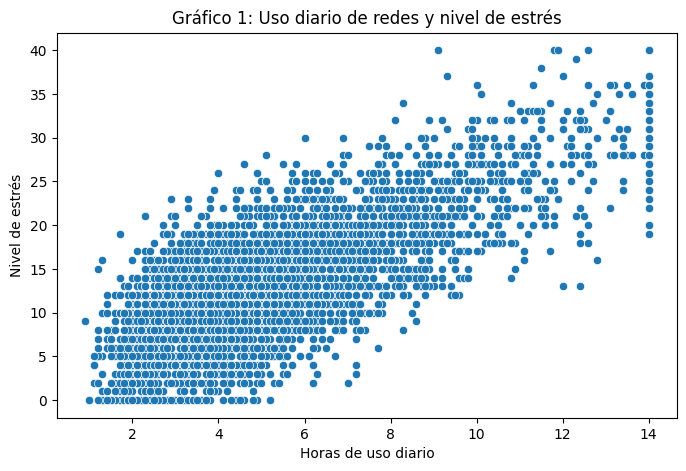

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df_impacto,
    x="Daily_Usage_Hours",
    y="Perceived_Stress_Score"
)

plt.title("Gráfico 1: Uso diario de redes y nivel de estrés")
plt.xlabel("Horas de uso diario")
plt.ylabel("Nivel de estrés")

plt.show()

El gráfico 1 nos muestras que a medida que aumenta las horas de uso de redes sociales también lo hace el nivel de estrés.

## Objetivo 2: ¿Cuál es la calidad de sueño que presentan los estudiantes que utilizan las redes sociales durante la noche?

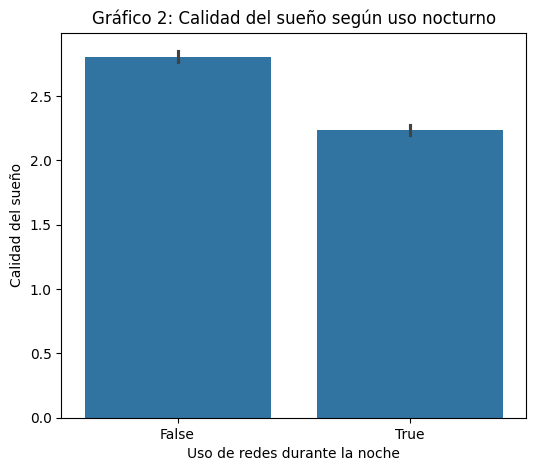

In [ ]:
plt.figure(figsize=(6,5))

sns.barplot(
    data=df_impacto,
    x="Late_Night_Usage",
    y="Sleep_Quality_Score")

plt.title("Gráfico 2: Calidad del sueño según uso nocturno")
plt.xlabel("Uso de redes durante la noche")
plt.ylabel("Calidad del sueño")

plt.show()

El gráfico 2 indica que los estudiantes que utilizan redes sociales durante la noche (True) tienen una calidad de sueño promedio más baja que aquellos que no las utilizan.

## Objetivo 3: ¿Cuál es la plataforma más utilizada por los estudiantes según su nivel académico?

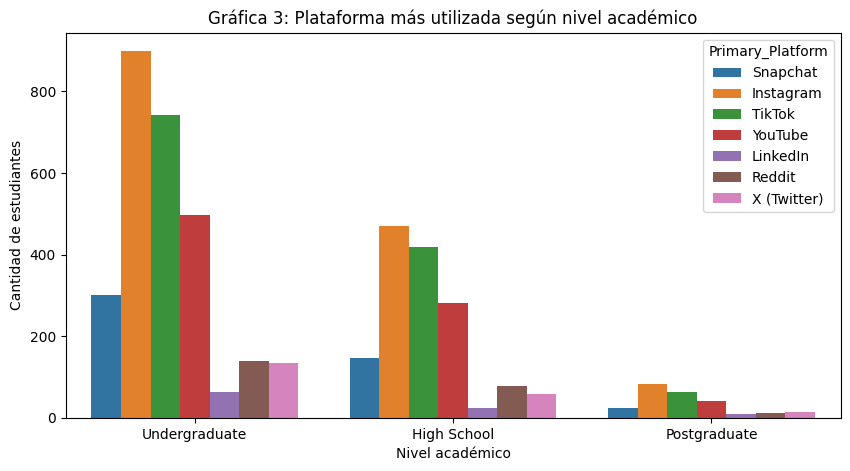

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df_impacto,
    x="Academic_Level",
    hue="Primary_Platform"
)

plt.title("Gráfica 3: Plataforma más utilizada según nivel académico")
plt.xlabel("Nivel académico")
plt.ylabel("Cantidad de estudiantes")

plt.show()

El gráfico 3 muestra que Instagram es la plataforma más utilizada dentro de cada nivel académico.

## Obejtivo 4: ¿Cómo varía el rendimiento académico según el tiempo de uso de las redes sociales?

/tmp/ipykernel_2237/2694930153.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  gpa_promedio = df_impacto.groupby("Grupo_Uso")["Academic_Performance_GPA"].mean()


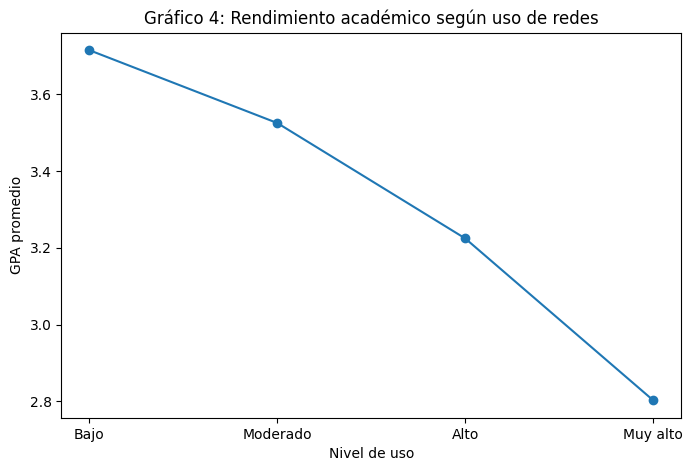

In [ ]:
# Crear grupos de horas
df_impacto["Grupo_Uso"] = pd.cut(
    df_impacto["Daily_Usage_Hours"],
    bins=[0, 3, 6, 9, 15],
    labels=["Bajo", "Moderado", "Alto", "Muy alto"])

gpa_promedio = df_impacto.groupby("Grupo_Uso")["Academic_Performance_GPA"].mean()

plt.figure(figsize=(8,5))
plt.plot(gpa_promedio.index, gpa_promedio.values, marker="o")

plt.title("Gráfico 4: Rendimiento académico según uso de redes")
plt.xlabel("Nivel de uso")
plt.ylabel("GPA promedio")

plt.show()

El gráfico 4 indica que a medida que aumenta el tiempo de uso de las redes sociales, el GPA promedio tiende a disminuir.

# Parte IV: Conclusiones


El análisis realizado muestra que un mayor uso de las redes sociales se relaciona con niveles de estrés más altos, menor calidad del sueño y un menor rendimiento académico. Los resultados sugieren que el uso excesivo de las redes sociales puede estar asociado con efectos desfavorables en la vida académica y personal de los estudiantes.